In [11]:
import sys, pkgutil
print(sys.executable)              # should point to .venv/bin/python or conda env python
print(sys.version)
print(sorted({m.name for m in pkgutil.iter_modules()} & {"tensorflow","torch","pandas"}))


/opt/anaconda3/bin/python
3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 10:07:17) [Clang 14.0.6 ]
['pandas']


In [18]:
#%pip install "tensorflow-macos>=2.16,<2.19" "tensorflow-metal>=1.1"

  Using cached tensorflow_macos-2.16.2-cp312-cp312-macosx_12_0_arm64.whl.metadata (3.3 kB)
  Using cached tensorflow_metal-1.2.0-cp312-cp312-macosx_12_0_arm64.whl.metadata (1.3 kB)
  Using cached tensorflow-2.16.2-cp312-cp312-macosx_12_0_arm64.whl.metadata (4.1 kB)
  Using cached absl_py-2.3.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.2.10-py2.py3-none-any.whl.metadata (875 bytes)
  Using cached gast-0.6.0-py3-none-any.whl.metadata (1.3 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-1-py2.py3-none-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached ml_dtypes-0.3.2-cp312-cp312-macosx_10_9_universal2.whl.metadata (20 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-4.25.8-cp37-abi3-macosx_10_9_universal2.whl.metadata (541 bytes)
  Using cached tensorboard-2.16.2-py3-none-any.whl.metadata 

In [6]:
#%pip install tensorflow_decision_forests wurlitzer

INFO: pip is looking at multiple versions of tf-keras to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 9.3 MB/s eta 0:00:0000:01m0:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 252.7/252.7 MB 2.0 MB/s eta 0:00:0000:0100:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 2.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 2.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 663.9/663.9 kB 2.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 418.1/418.1 kB 1.6 MB/s eta 0:00:00a 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 2.7 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: protobuf
    Found existing installation: protobuf 4.25.8
    Uninstalling protobuf-4.25.8:
      Successfully uninstalled protobuf-4.25.8
  Attempting uninstall: ml-dtypes
    Found existing installation: ml-dtypes 

## Import Libraries

In [2]:
import tensorflow as tf
import tensorflow_decision_forests as tfdf
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set up notebook to display multiple outputs in one cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
from IPython.display import display

# Comment this if the data visualisations doesn't work on your side
%matplotlib inline

In [4]:
print("TensorFlow v" + tf.__version__)
print("TensorFlow Decision Forests v" + tfdf.__version__)

TensorFlow v2.19.0
TensorFlow Decision Forests v1.12.0


# Load Datasets

In [8]:
train_file_path = "/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/train.csv"
dataset_df = pd.read_csv(train_file_path)
print("Full train dataset shape is {}".format(dataset_df.shape))

Full train dataset shape is (1460, 81)


In [10]:
dataset_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [12]:
dataset_df = dataset_df.drop('Id', axis=1)
dataset_df.head(3)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [14]:
dataset_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

## Housing Price Distribution

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_96440/3430012634.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset_df['SalePrice'], color='g', bins=100, hist_kws={'alpha': 0.4});


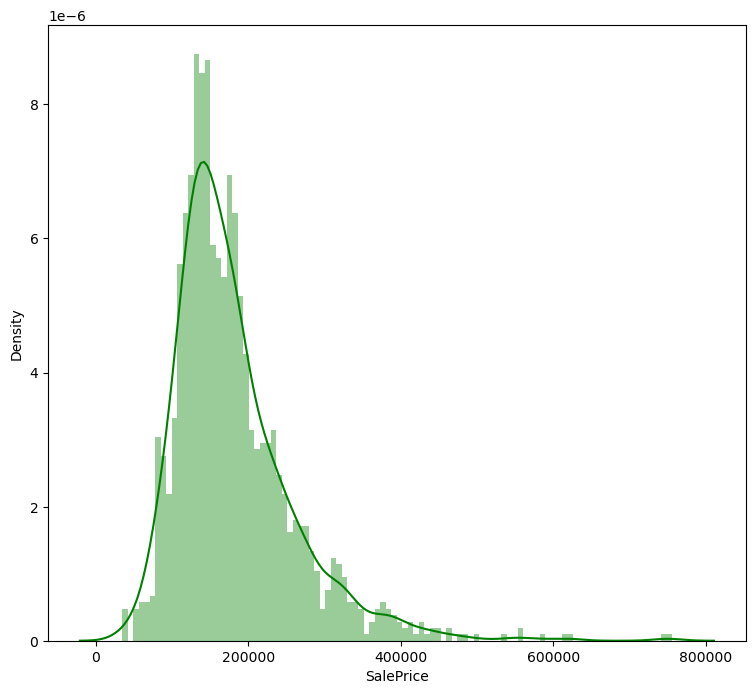

In [16]:
print(dataset_df['SalePrice'].describe())
plt.figure(figsize=(9, 8))
sns.distplot(dataset_df['SalePrice'], color='g', bins=100, hist_kws={'alpha': 0.4});

## Numerical Data Distribution

In [18]:
list(set(dataset_df.dtypes.tolist()))

[dtype('int64'), dtype('O'), dtype('float64')]

In [20]:
df_num = dataset_df.select_dtypes(include = ['float64', 'int64'])
df_num.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,61,0,0,0,0,0,2,2008,208500
1,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,298,0,0,0,0,0,0,5,2007,181500
2,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,42,0,0,0,0,0,9,2008,223500
3,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,35,272,0,0,0,0,2,2006,140000
4,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,192,84,0,0,0,0,0,12,2008,250000


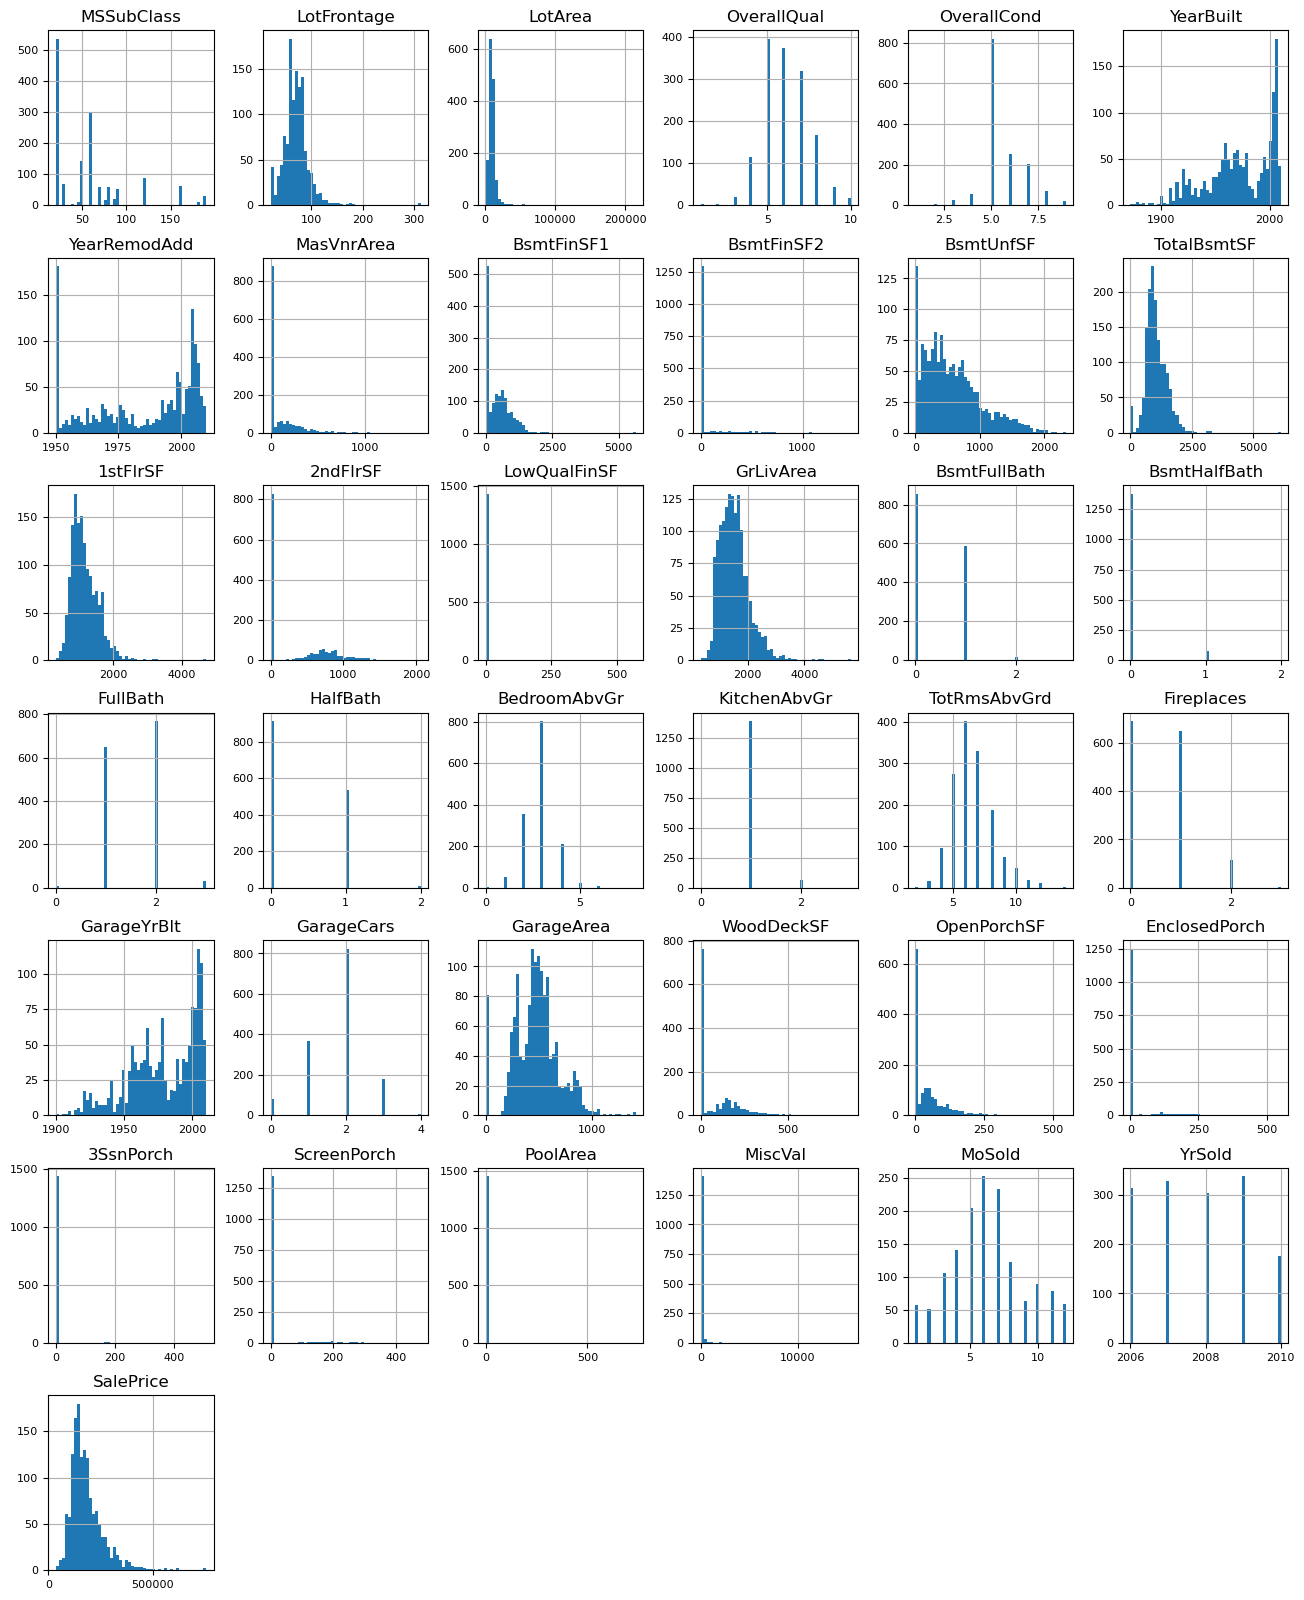

In [22]:
df_num.hist(figsize=(16, 20), bins=50, xlabelsize=8, ylabelsize=8);

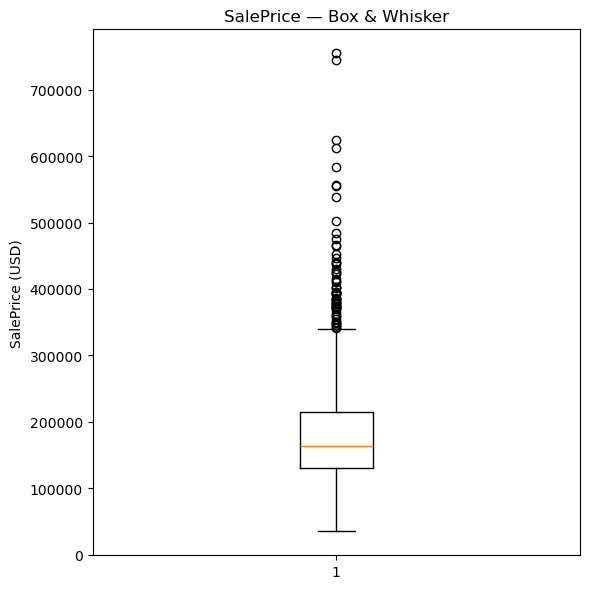

In [24]:
import matplotlib.pyplot as plt

# Ensure the column exists and is numeric
sp = dataset_df["SalePrice"].dropna()

plt.figure(figsize=(6, 6))
plt.boxplot(sp, vert=True, showfliers=True) 
plt.title("SalePrice — Box & Whisker")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show();

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = dataset_df.copy()

def corr_summary(x, y):
    """Print Pearson and Spearman correlations (drop NA & align indices)."""
    data = pd.DataFrame({"x": x, "y": y}).dropna()
    pearson = data["x"].corr(data["y"], method="pearson")
    spearman = data["x"].corr(data["y"], method="spearman")
    print(f"n={len(data)} | Pearson r={pearson:.3f} | Spearman ρ={spearman:.3f}")

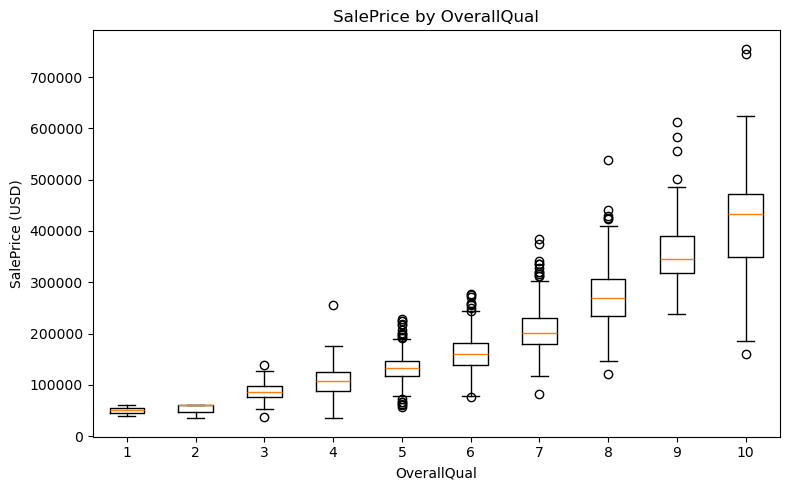

n=1460 | Pearson r=0.791 | Spearman ρ=0.810
             Median_SalePrice
OverallQual                  
1                     50150.0
2                     60000.0
3                     86250.0
4                    108000.0
5                    133000.0
6                    160000.0
7                    200141.0
8                    269750.0
9                    345000.0
10                   432390.0


In [28]:
y = df["SalePrice"]
x = df["OverallQual"]

# Boxplot by quality (categorical on x)
groups = [y[x == q].dropna() for q in sorted(x.dropna().unique())]

plt.figure(figsize=(8, 5))
plt.boxplot(groups, showfliers=True)
plt.title("SalePrice by OverallQual")
plt.xlabel("OverallQual")
plt.ylabel("SalePrice (USD)")
plt.xticks(ticks=range(1, len(groups)+1), labels=sorted(x.dropna().unique()))
plt.tight_layout()
plt.show()

# Correlations (treat OverallQual as ordinal numeric)
corr_summary(x, y)

# Median table (quick effect size by level)
med_table = (
    df.groupby("OverallQual")["SalePrice"]
      .median()
      .rename("Median_SalePrice")
      .to_frame()
      .sort_index()
)
print(med_table.head(10));

<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'SalePrice vs. GrLivArea')

Text(0.5, 0, 'GrLivArea (sq ft)')

Text(0, 0.5, 'SalePrice (USD)')

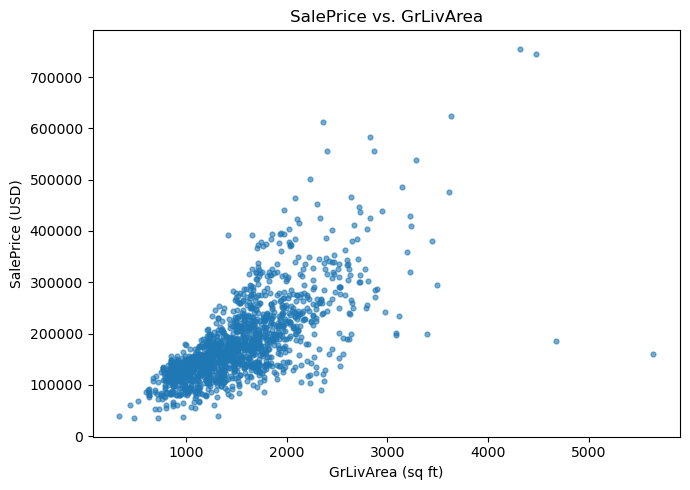

<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'SalePrice vs. GrLivArea (with linear fit)')

Text(0.5, 0, 'GrLivArea (sq ft)')

Text(0, 0.5, 'SalePrice (USD)')

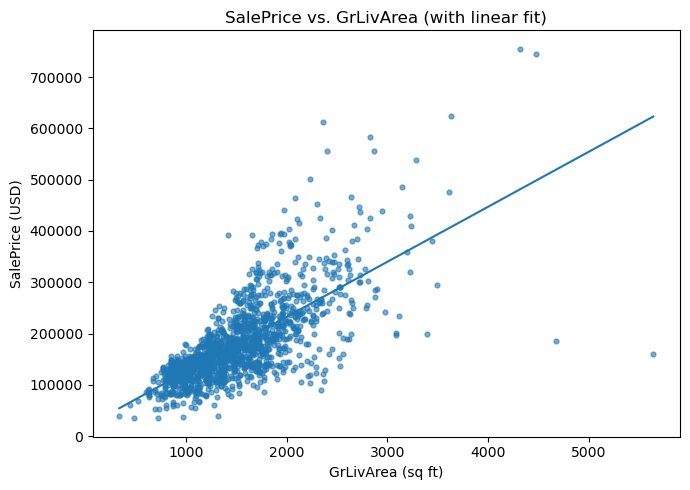

n=1460 | Pearson r=0.709 | Spearman ρ=0.731


<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'log(SalePrice) vs. log(GrLivArea)')

Text(0.5, 0, 'log(1 + GrLivArea)')

Text(0, 0.5, 'log(1 + SalePrice)')

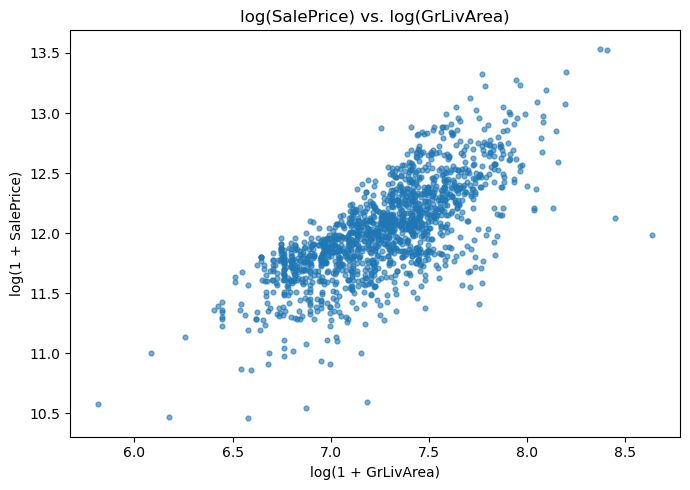

Log-space correlations:
n=1460 | Pearson r=0.730 | Spearman ρ=0.731


In [30]:
x = df["GrLivArea"]
y = df["SalePrice"]

# Basic scatter
plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=12, alpha=0.6)
plt.title("SalePrice vs. GrLivArea")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show()

# Add a simple linear fit line (least squares)
mask = x.notna() & y.notna()
coeffs = np.polyfit(x[mask], y[mask], deg=1)
xline = np.linspace(x[mask].min(), x[mask].max(), 200)
yline = coeffs[0] * xline + coeffs[1]

plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=12, alpha=0.6)
plt.plot(xline, yline)
plt.title("SalePrice vs. GrLivArea (with linear fit)")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show();

# Correlations (linear + rank)
corr_summary(x, y)

# log-transform (often tightens relationship)
x_log = np.log1p(x)
y_log = np.log1p(y)
plt.figure(figsize=(7, 5))
plt.scatter(x_log, y_log, s=12, alpha=0.6)
plt.title("log(SalePrice) vs. log(GrLivArea)")
plt.xlabel("log(1 + GrLivArea)")
plt.ylabel("log(1 + SalePrice)")
plt.tight_layout()
plt.show();

print("Log-space correlations:")
corr_summary(x_log, y_log)


<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'SalePrice vs. TotalBsmtSF')

Text(0.5, 0, 'TotalBsmtSF (sq ft)')

Text(0, 0.5, 'SalePrice (USD)')

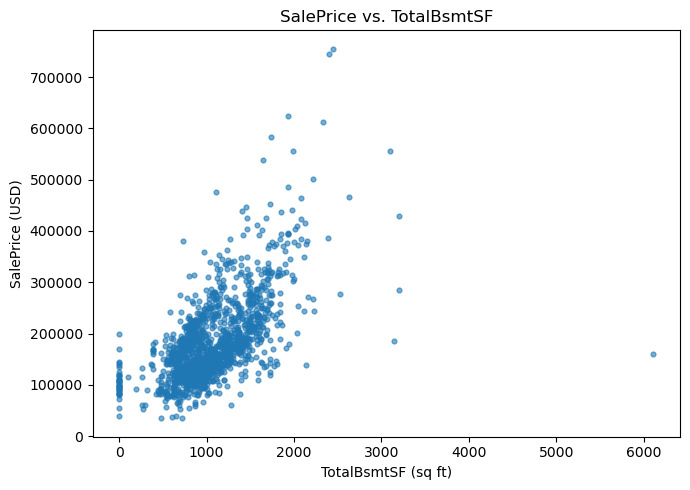

n=1460 | Pearson r=0.614 | Spearman ρ=0.603


<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'SalePrice vs. TotalBsmtSF (non-zero basements)')

Text(0.5, 0, 'TotalBsmtSF (sq ft)')

Text(0, 0.5, 'SalePrice (USD)')

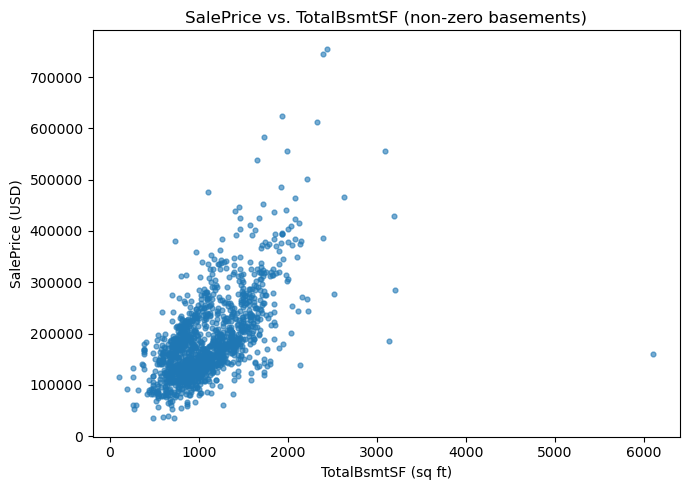

Non-zero basements only:
n=1423 | Pearson r=0.610 | Spearman ρ=0.583


<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'log(SalePrice) vs. log(TotalBsmtSF) (non-zero)')

Text(0.5, 0, 'log(1 + TotalBsmtSF)')

Text(0, 0.5, 'log(1 + SalePrice)')

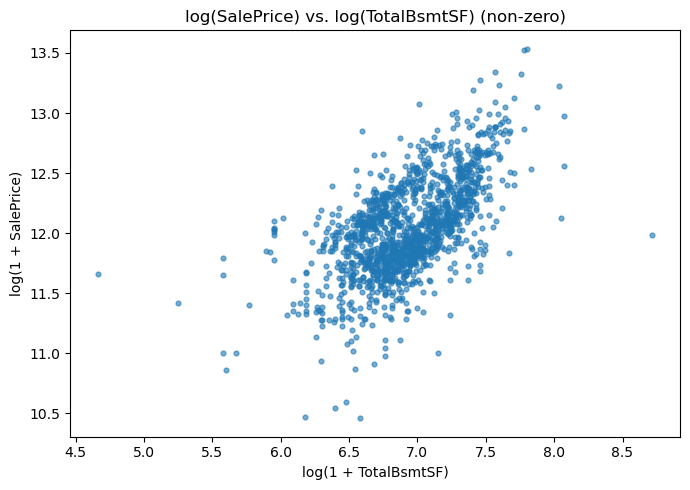

Log-space (non-zero):
n=1423 | Pearson r=0.605 | Spearman ρ=0.583


In [32]:
x = df["TotalBsmtSF"]
y = df["SalePrice"]

# Base scatter
plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=12, alpha=0.6)
plt.title("SalePrice vs. TotalBsmtSF")
plt.xlabel("TotalBsmtSF (sq ft)")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show()

corr_summary(x, y)

# exclude zero basements to see linear trend among non-zeros
nz = x > 0
plt.figure(figsize=(7, 5))
plt.scatter(x[nz], y[nz], s=12, alpha=0.6)
plt.title("SalePrice vs. TotalBsmtSF (non-zero basements)")
plt.xlabel("TotalBsmtSF (sq ft)")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show()

print("Non-zero basements only:")
corr_summary(x[nz], y[nz])

# log-space among non-zeros
x_log = np.log1p(x[nz])
y_log = np.log1p(y[nz])
plt.figure(figsize=(7, 5))
plt.scatter(x_log, y_log, s=12, alpha=0.6)
plt.title("log(SalePrice) vs. log(TotalBsmtSF) (non-zero)")
plt.xlabel("log(1 + TotalBsmtSF)")
plt.ylabel("log(1 + SalePrice)")
plt.tight_layout()
plt.show()

print("Log-space (non-zero):")
corr_summary(x_log, y_log)

## Size x Quality

Quality amplifies the value of square footage

In [34]:
df = dataset_df.copy()

# centered quality so 0 ≈ average quality (5–6)
q = (df["OverallQual"] - df["OverallQual"].median())

df["QualAdj_LivArea"]   = df["GrLivArea"] * (1 + 0.08*q)        # ~8% per quality notch
df["QualAdj_TotArea"]   = (df["GrLivArea"] + df["TotalBsmtSF"]) * (1 + 0.08*q)
df["QualSq_LivArea"]    = df["GrLivArea"] * (df["OverallQual"]**2)  # nonlinear variant


## Finished space focus

Finished area tends to price stronger than unfinished

In [38]:
df["FinishedSF"] = (
    df["GrLivArea"] 
    + df["BsmtFinSF1"].fillna(0) 
    + df["BsmtFinSF2"].fillna(0)
)
df["FinishedShare"] = df["FinishedSF"] / (df["GrLivArea"] + df["TotalBsmtSF"]).replace(0, np.nan)


## Bathrooms & utility

Bathrooms capture livability better than simple room counts

In [40]:
df["TotalBaths"] = (
    df["FullBath"] 
    + 0.5*df["HalfBath"] 
    + df["BsmtFullBath"] 
    + 0.5*df["BsmtHalfBath"]
)
df["Baths_per_1000sf"] = df["TotalBaths"] / (df["GrLivArea"]/1000)


## Age & condition

Price usually declines with age, but remodels offset it

In [42]:
sale_year = df["YrSold"]
df["HouseAge"]      = sale_year - df["YearBuilt"]
df["YearsSinceReno"]= sale_year - df["YearRemodAdd"]
df["IsRemodeled"]   = (df["YearRemodAdd"] > df["YearBuilt"]).astype(int)

# Interaction: newer + higher quality
df["NewerHighQual"] = (-(df["HouseAge"])) * df["OverallQual"]


## Garage value

Capacity often matters more than raw square footage

In [44]:
df["GarageScore"] = (
    1.0*df["GarageCars"] 
    + 0.001*df["GarageArea"]            # small tie-breaker
)
df["HasGarage"] = (df["GarageCars"] > 0).astype(int)


## Outdoor/amenity bundle

Porches and decks have small, additive effects

In [46]:
df["PorchDeckSF"] = (
    df["WoodDeckSF"] + df["OpenPorchSF"] + df["EnclosedPorch"] 
    + df["3SsnPorch"] + df["ScreenPorch"]
)
df["AmenityCount"] = (
    (df["Fireplaces"]>0).astype(int)
    + (df["PorchDeckSF"]>0).astype(int)
    + (df["PoolArea"]>0).astype(int)
)


## Neighborhood signal (leak-safe target encoding)

Neighborhood is powerful but high-cardinality. Use out-of-fold target means to avoid leakage

In [48]:
from sklearn.model_selection import KFold
import numpy as np
import pandas as pd

def kfold_target_encode(frame, col, target="SalePrice", n_splits=5, noise=0.0):
    out = pd.Series(index=frame.index, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    for tr, te in kf.split(frame):
        means = frame.iloc[tr].groupby(col)[target].mean()
        out.iloc[te] = frame.iloc[te][col].map(means)
    # global prior for unseen levels
    prior = frame[target].mean()
    out = out.fillna(prior)
    if noise:
        out *= (1 + noise*np.random.randn(len(out)))
    return out

df["NBH_price_oof"] = kfold_target_encode(df, "Neighborhood")


## Seasonality of sale

In some markets, month matters

In [50]:
df["Season_Flag"] = pd.cut(
    df["MoSold"], bins=[0,2,5,8,11,12], labels=["Jan-Feb","Mar-May","Jun-Aug","Sep-Nov","Dec"], right=True
)
# One-hot encode later, or target encode like Neighborhood.


## Ratios & sanity checks

Ratios stabilize scale and reduce heteroscedasticity

In [52]:
df["Price_per_SF_proxy"] = df["SalePrice"] / df["GrLivArea"]  # use only for EDA, NOT as a model input with SalePrice
df["RoomsPer1000SF"]     = df["TotRmsAbvGrd"] / (df["GrLivArea"]/1000)
df["BedsPerBath"]        = df["BedroomAbvGr"]/df["TotalBaths"].replace(0,np.nan)


## Transformations that help most models

In [54]:
for col in ["SalePrice","GrLivArea","FinishedSF","TotalBsmtSF","PorchDeckSF"]:
    df[f"log1p_{col}"] = np.log1p(df[col].clip(lower=0))


In [56]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

y = np.log1p(df["SalePrice"])  # model log-price
num_feats = [
    "GrLivArea","OverallQual","TotalBsmtSF","FinishedSF","FinishedShare",
    "TotalBaths","GarageScore","PorchDeckSF","NBH_price_oof",
    "QualAdj_LivArea","QualAdj_TotArea","NewerHighQual"
]
X = df[num_feats].fillna(0)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])
scores = cross_val_score(pipe, X, y, cv=5, scoring="r2")
print("CV R^2 (mean±std):", scores.mean().round(3), "±", scores.std().round(3))


CV R^2 (mean±std): 0.846 ± 0.022


In [58]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# assume your DataFrame is dataset_df
y = dataset_df[["SalePrice"]]   # keep as 2D for sklearn

# --- Min-Max Scaling (scales to [0,1]) ---
minmax_scaler = MinMaxScaler()
y_minmax = minmax_scaler.fit_transform(y)

# --- Standard Scaling (z-score: mean=0, std=1) ---
standard_scaler = StandardScaler()
y_standard = standard_scaler.fit_transform(y)

# Put back into a DataFrame for readability
scaled_y = pd.DataFrame({
    "SalePrice": y["SalePrice"].values,
    "SalePrice_minmax": y_minmax.flatten(),
    "SalePrice_standard": y_standard.flatten()
})

print(scaled_y.head())


   SalePrice  SalePrice_minmax  SalePrice_standard
0     208500          0.241078            0.347273
1     181500          0.203583            0.007288
2     223500          0.261908            0.536154
3     140000          0.145952           -0.515281
4     250000          0.298709            0.869843


## RandomForestModel

## Prepare the dataset

This dataset contains a mix of numeric, categorical and missing features. TF-DF supports all these feature types natively, and no preprocessing is required. This is one advantage of tree-based models, making them a great entry point to Tensorflow and ML

In [60]:
import numpy as np

def split_dataset(dataset, test_ratio=0.30):
    test_indices = np.random.rand(len(dataset)) < test_ratio
    return dataset[~test_indices], dataset[test_indices]

train_ds_pd, valid_ds_pd = split_dataset(dataset_df)
print("{} examples in training, {} examples in testing.".format(
    len(train_ds_pd), len(valid_ds_pd)))

1027 examples in training, 433 examples in testing.


In [62]:
label = 'SalePrice'
train_ds = tfdf.keras.pd_dataframe_to_tf_dataset(train_ds_pd, label=label, task = tfdf.keras.Task.REGRESSION)
valid_ds = tfdf.keras.pd_dataframe_to_tf_dataset(valid_ds_pd, label=label, task = tfdf.keras.Task.REGRESSION)

2025-09-24 20:34:07.227844: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Pro
2025-09-24 20:34:07.228088: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 18.00 GB
2025-09-24 20:34:07.228097: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 6.00 GB
I0000 00:00:1758771247.228435 12785993 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1758771247.228775 12785993 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


## Select a Model

There are several tree-based models for you to choose from:
- RandomForestModel
- GradientBoostedTreesModel
- CartModel
- DistributedGradientBoostedTreesModel

We'll work with a Random Forest. This is the most well-known of the Decision Forest training algorithms. 

A Random Forest is a collection of decision trees, each trained independently on a random subset of the training dataset (sampled with replacement). The algorithm is unique in that it is robust to overfitting, and easy to use. 

In [64]:
tfdf.keras.get_all_models()

[tensorflow_decision_forests.keras.RandomForestModel,
 tensorflow_decision_forests.keras.GradientBoostedTreesModel,
 tensorflow_decision_forests.keras.CartModel,
 tensorflow_decision_forests.keras.DistributedGradientBoostedTreesModel]

## Create a Random Forest

In [66]:
rf = tfdf.keras.RandomForestModel(task = tfdf.keras.Task.REGRESSION)
rf.compile(metrics=["mse"]) # optional, you can use this to include a list of eval metrics

Use /var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/tmpf6pu8t2r as temporary training directory


## Train the Model

We will train the model using a one-liner

In [68]:
rf.fit(x=train_ds)

Reading training dataset...


2025-09-24 20:34:20.939887: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Training dataset read in 0:00:01.690080. Found 1027 examples.
Training model...


I0000 00:00:1758771261.202541 12785993 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1758771261.202593 12785993 kernel.cc:783] Collect training examples
I0000 00:00:1758771261.202599 12785993 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: NUMERICAL
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1758771261.202911 12785993 kernel.cc:401] Number of batches: 2
I0000 00:00:1758771261.202915 12785993 kernel.cc:402] Number of examples: 1027
I0000 00:00:1758771261.203721 12785993 data_spec_inference.cc:354] 1 item(s) have been pruned (i.e. they are considered out of dictionary) for the column BsmtCond (3 item(s) left) because min_value_count=5 and max_number_of_unique_values=2000
I0000 00:00:1758771261.203732 12785993 data_spec_inference.cc:354] 2 item(s) have be

Model trained in 0:00:00.379864
Compiling model...


I0000 00:00:1758771261.433939 12795013 kernel.cc:926] Export model in log directory: /var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/tmpf6pu8t2r with prefix 83fd25aa59834013
I0000 00:00:1758771261.459598 12795013 kernel.cc:944] Save model in resources
I0000 00:00:1758771261.462997 12785993 abstract_model.cc:921] Model self evaluation:
Number of predictions (without weights): 1027
Number of predictions (with weights): 1027
Task: REGRESSION
Label: __LABEL

RMSE: 29739.1 CI95[X2][28506.8 31083.5]
Default RMSE: : 76957.3

2025-09-24 20:34:21.487036: I tensorflow_decision_forests/tensorflow/ops/inference/kernel.cc:1206] Loading model from path /var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/tmpf6pu8t2r/model/ with prefix 83fd25aa59834013
I0000 00:00:1758771261.574952 12785993 decision_forest.cc:808] Model loaded with 300 root(s), 97722 node(s), and 75 input feature(s).
I0000 00:00:1758771261.574989 12785993 abstract_model.cc:1439] Engine "RandomForestOptPred" built
2025-09-24 20:34:21.574

Model compiled.


## Visualize the Model

One benefit of tree-based models is that you can easily visualize them. The default number of trees used in the Random Forest is 300. We can select a tree to display below.

In [70]:
tfdf.model_plotter.plot_model_in_colab(rf, tree_idx=0, max_depth=3)

## Evaluate the model on the Out of bag (OOB) data and the validation dataset

Before training the dataset we have manually separated 20% of the dataset for validation named as valid_ds. 

We can also use Out of bag (OOB) score to validate our RandomForestModel. To train a Random Forest Model, a set of random samples from training set are chosen by the algorithm and the rest of the samples are used to fintune the model. The subset of data that is not chosen is known as Out of bag (OOB). OOB score is computed on the OOB data. 

The training logs show the Root Mean Squared Error (RMSE) evaluated on the out-of-bag dataset according to the number of trees in the model. We'll plot this

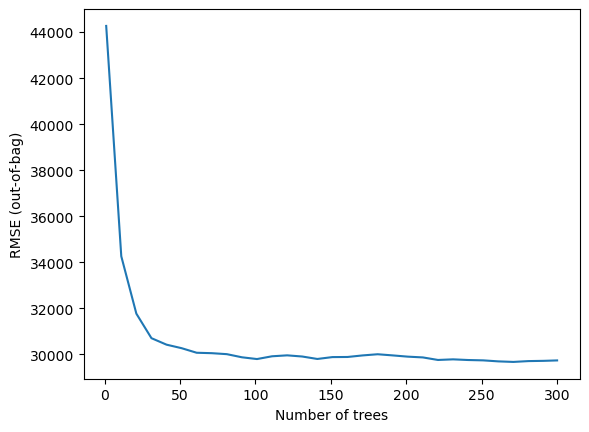

In [72]:
import matplotlib.pyplot as plt
logs = rf.make_inspector().training_logs()
plt.plot([log.num_trees for log in logs], [log.evaluation.rmse for log in logs])
plt.xlabel("Number of trees")
plt.ylabel("RMSE (out-of-bag)")
plt.show();

In [74]:
inspector = rf.make_inspector()
inspector.evaluation()

Evaluation(num_examples=1027, accuracy=None, loss=None, rmse=29739.085548286963, ndcg=None, aucs=None, auuc=None, qini=None)

In [76]:
evaluation = rf.evaluate(x=valid_ds, return_dict=True)

for name, value in evaluation.items():
    print(f"{name}: {value:.4f}")

1/1 [==============================] - 1s 608ms/step - loss: 0.0000e+00 - mse: 963051072.0000
loss: 0.0000
mse: 963051072.0000


## Variable importances

Variables importances generally indicate how much a feature contributes to the model predictions or quality. There are several ways to identify features using TensorFlow Decision Forests. Let us list the available Variable Importances for Decision Trees: 

In [78]:
print(f"Available variable importances:")
for importance in inspector.variable_importances().keys():
    print("\t", importance)

Available variable importances:
	 NUM_NODES
	 INV_MEAN_MIN_DEPTH
	 NUM_AS_ROOT
	 SUM_SCORE


As an example, let us display the important features for the Variable Importance NUM_AS_ROOT. 

The larger the importance score for NUM_AS_ROOT, the more impact it has on the outcome of the model. 

By default, the list is sorted from the most important to the least. From the output you can infer that the feature at the top of the list is used as the root node in most number of trees in the random forest than any other feature. 

In [80]:
inspector.variable_importances()["NUM_AS_ROOT"]

[("OverallQual" (1; #62), 121.0),
 ("ExterQual" (4; #22), 49.0),
 ("Neighborhood" (4; #59), 42.0),
 ("GrLivArea" (1; #38), 23.0),
 ("GarageCars" (1; #32), 18.0),
 ("YearBuilt" (1; #76), 18.0),
 ("KitchenQual" (4; #44), 10.0),
 ("1stFlrSF" (1; #0), 6.0),
 ("TotalBsmtSF" (1; #73), 6.0),
 ("BsmtQual" (4; #14), 3.0),
 ("FullBath" (1; #29), 2.0),
 ("GarageYrBlt" (1; #37), 2.0)]

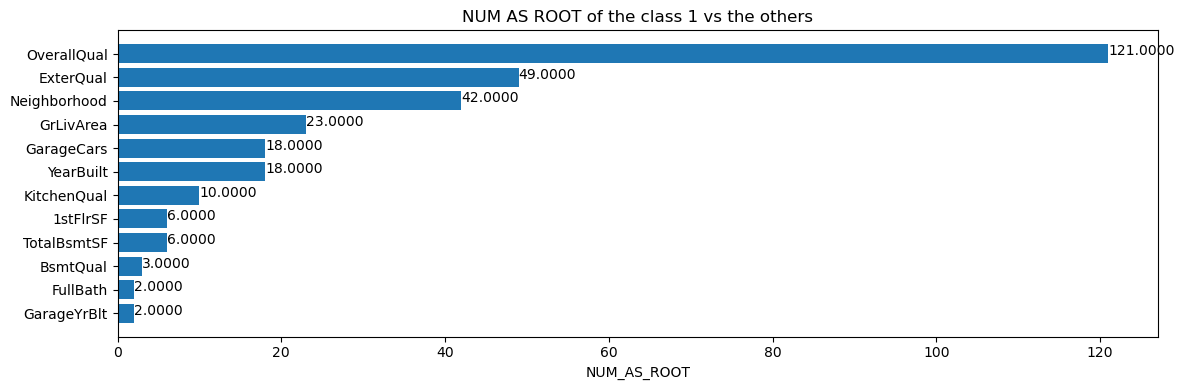

In [82]:
plt.figure(figsize=(12, 4))

# Mean decrease in AUC of the class 1 vs the others
variable_importance_metric = "NUM_AS_ROOT"
variable_importances = inspector.variable_importances()[variable_importance_metric]

# Extract the feature name and importance values

# 'variable_importances' is a list of <feature, importance> tuples
feature_names = [vi[0].name for vi in variable_importances]
feature_importances = [vi[1] for vi in variable_importances]
# The feature are ordered in decreasing importance value.
feature_ranks = range(len(feature_names))

bar = plt.barh(feature_ranks, feature_importances, label=[str(x) for x in feature_ranks])
plt.yticks(feature_ranks, feature_names)
plt.gca().invert_yaxis()

# TODO: replace with "plt.bar_label()" when available
# Label each bar with values
for importance, patch in zip(feature_importances, bar.patches):
    plt.text(patch.get_x() + patch.get_width(), patch.get_y(), f"{importance:.4f}", va="top")

plt.xlabel(variable_importance_metric)
plt.title("NUM AS ROOT of the class 1 vs the others")
plt.tight_layout()
plt.show();

## Submission

Finally predict on the competition test data using the model

In [86]:
test_file_path = "/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/test.csv"
test_data = pd.read_csv(test_file_path)
ids = test_data.pop('Id')

test_ds = tfdf.keras.pd_dataframe_to_tf_dataset(
    test_data,
    task = tfdf.keras.Task.REGRESSION)

preds = rf.predict(test_ds)
output = pd.DataFrame({'Id': ids,
                       'SalePrice': preds.squeeze()})

output.head()

2/2 [==============================] - 0s 37ms/step


,Id,SalePrice
0,1461,123744.929688
1,1462,154125.031250
2,1463,184056.828125
3,1464,184764.968750
4,1465,196387.453125


In [88]:
# 1) Read the Kaggle template
sample_submission_df = pd.read_csv(
    "/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/sample_submission.csv"
)

# 2) Get predictions (make sure test_ds has the same feature columns the model was trained on)
preds = rf.predict(test_ds, verbose=0).squeeze()   # -> shape (n,)

# 3) Fill and save
sample_submission_df["SalePrice"] = preds
sample_submission_df.to_csv("RandomForestModel.csv", index=False)
sample_submission_df.head()


,Id,SalePrice
0,1461,123744.929688
1,1462,154125.031250
2,1463,184056.828125
3,1464,184764.968750
4,1465,196387.453125


## Regularized Linear Model

For Cross-Validation

In [224]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib

import matplotlib.pyplot as plt
from scipy.stats import skew
from scipy.stats import pearsonr

%config InlineBackend.figure_format = 'retina' #set 'png' here when working on notebook
%matplotlib inline

In [226]:
train = pd.read_csv("/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/train.csv")
test = pd.read_csv("/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/test.csv")

In [228]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### Explanation

- This columns slice selects every column from MSSubClass through SaleCondition inclusive.
- This slice intentionally drops:
    - the left side: Id
    - the right side: the target SalePrice (exists only in train)
- Then you stack train and test features vertically into all_data
    - This is a common trick so you can apply the same preprocessing / encoding to both datasets at once

In [230]:
all_data = pd.concat((train.loc[:,'MSSubClass':'SaleCondition'],
                      test.loc[:,'MSSubClass':'SaleCondition']))

## Data Preprocessing

1. Transform the skewed numeric features by taking log(feature + 1) - this will make the features more normal
2. Create dummy variables for the categorical features
3. Replace the numeric missing values (NaN's) with the mean of their respective columns

#### Explanation of code below

- Sets a bigger default figure size and plots histograms of raw and log-transformed SalePrice
- Addresses Requirement #2 (EDA & visuals) and shows the log transform reduces right-skew - useful for linear models and RMSLE

array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'log(price + 1)'}>]], dtype=object)

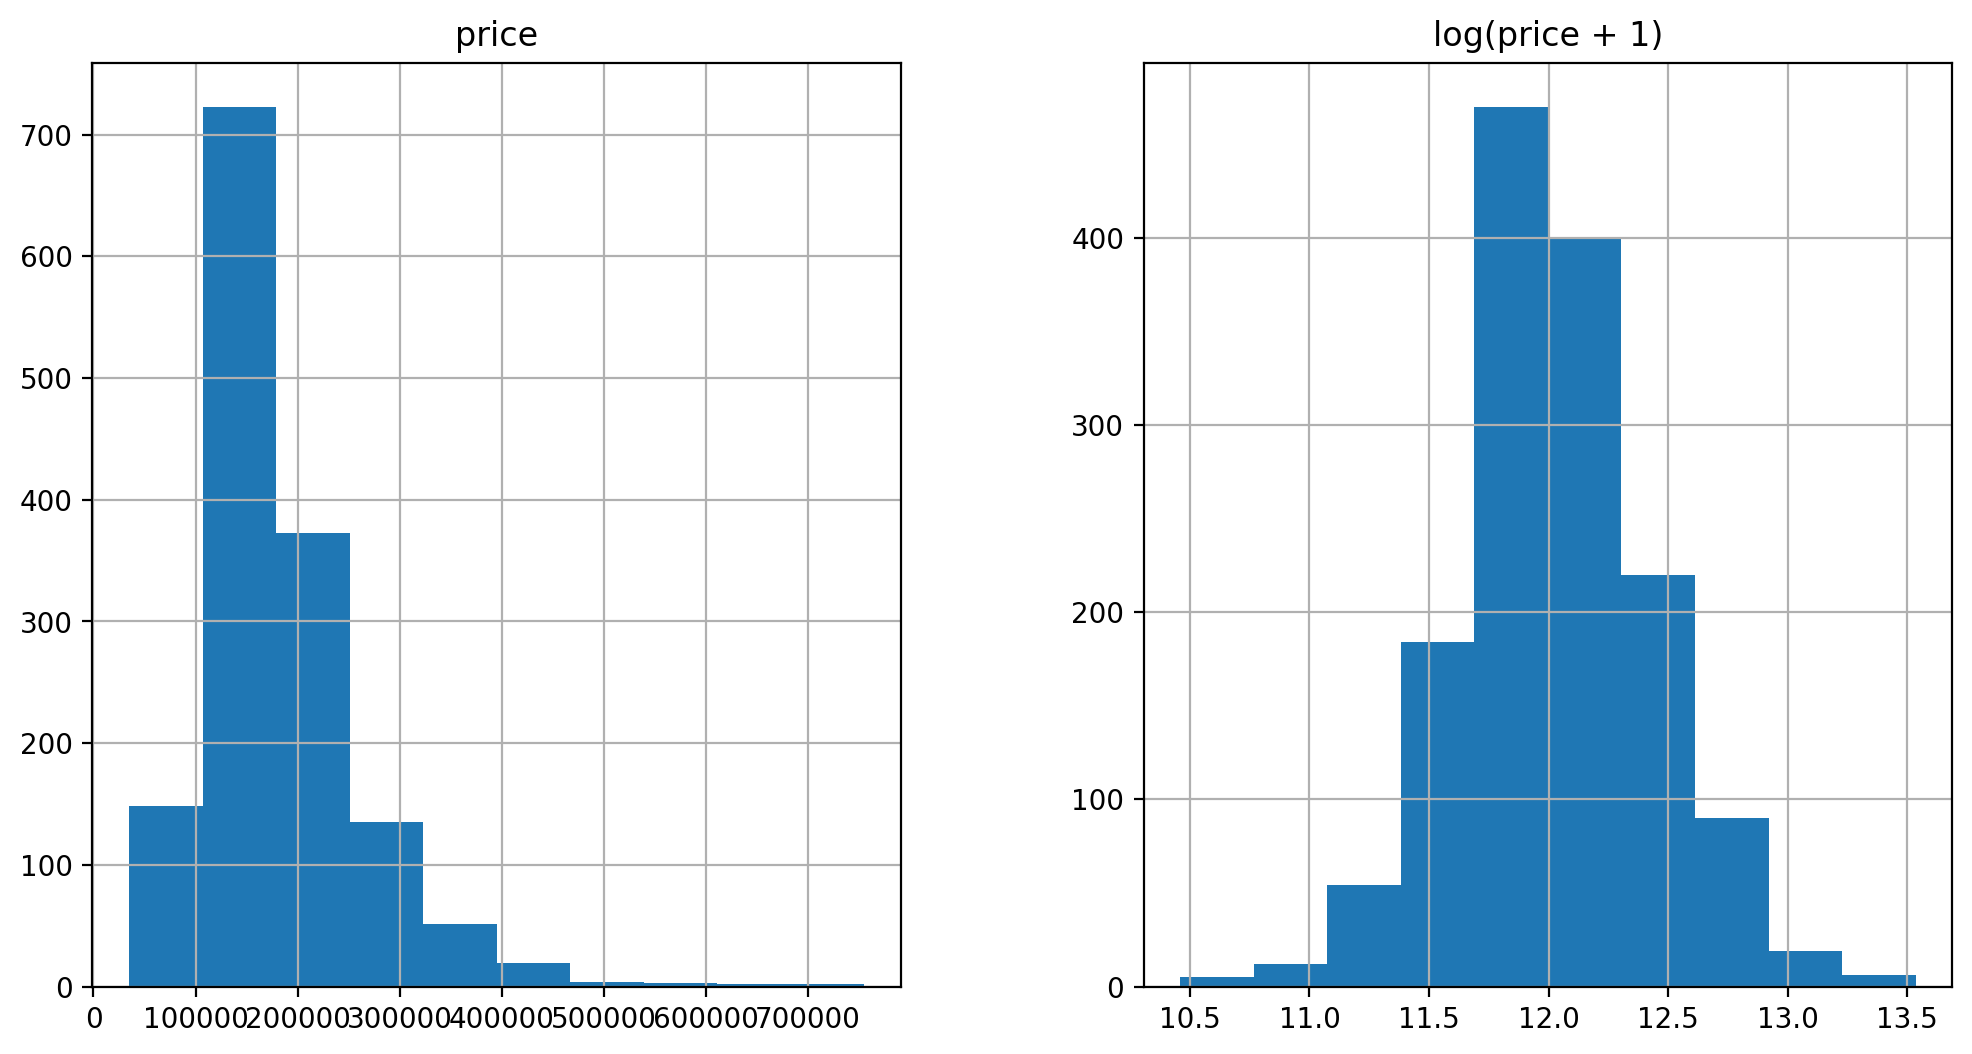

In [232]:
matplotlib.rcParams['figure.figsize'] = (12.0, 6.0)
prices = pd.DataFrame({"price":train["SalePrice"], "log(price + 1)":np.log1p(train["SalePrice"])})
prices.hist()

#### Explanation of code below

- Converts the target to log(SalePrice+1) in place
- Good for stabilizing variance and aligning with RMSLE
- Tip: keep the original for reporting / prediction
- Identifies numeric columns in your combined frame (all_data = train+test features). This list is the candidate for de-skewing
- Computes skew using training data only (good!) and selects features with skewnes > 0.75 (common Kaggle threshold)
- Sensible EDA-driven preprocessing (still part of Requirement #2)
- Applies log1p to the selected skewed features in both train and test so they are on the same scale
- Consistent transforms across splits

In [234]:
# log transform the target: 
train["SalePrice"] = np.log1p(train["SalePrice"])

# log transform skewed numeric features:
numeric_feats = all_data.dtypes[all_data.dtypes != "object"].index

skewed_feats = train[numeric_feats].apply(lambda x: skew(x.dropna())) # compute skewness
skewed_feats = skewed_feats[skewed_feats > 0.75]
skewed_feats = skewed_feats.index

all_data[skewed_feats] = np.log1p(all_data[skewed_feats])

#### Explanation of code below

- One-hot encodes all categories in the combined data, ensuring train / test get identical dummy columns
- Common Kaggle tactic

In [236]:
all_data = pd.get_dummies(all_data)

#### Explanation of code below

- Imputes missing values with the global mean computed on (train+test)
- Data leakage for cross-validation: imputing / statistics must be fit on training folds only, then applied to the validation fold and test. Computing means on all_data (which includes test) leaks information

In [238]:
# Filling NA's with the mean of the column
all_data = all_data.fillna(all_data.mean())

Note that above we use the all data to compute the mean value that is then used for imputation. This is a flawed approach since it introduces some minor data leakage. However, we decided to leave it here because it showcases some common mistakes we make

#### Explanation of code below

- Splits the processed matrix back to Train / Test by row count
- Uses y as the log-price (because we overwrote SalePrice above)
- Ready for modeling - but for regularized linear models, we'll also want feature scaling (Standard Scaler) done inside CV.

In [240]:
# Creating matrics for sklearn
X_train = all_data[:train.shape[0]]
X_test = all_data[train.shape[0]:]
y = train.SalePrice

## Models

Now we are going to use regularized linear regression models from the scikit learn module. We're going to try both l_1 (Lasso) and l_2 (Ridge) regularization. We'll also define a function that returns the cross-validation rmse error so we can evaluate our models and pick the best tuning par.

In [242]:
from sklearn.linear_model import Ridge, RidgeCV, ElasticNet, LassoCV, LassoLarsCV
from sklearn.model_selection import cross_val_score

def rmse_cv(model):
    rmse = np.sqrt(-cross_val_score(model, X_train, y, scoring="neg_mean_squared_error", cv = 5))
    return(rmse)

In [244]:
model_ridge = Ridge()

The main tuning parameter for the Ridge model is alpha - a regularization parameter that measures how flexible our model is. The higher the regularization the less prone our model will be to overfit. However it will also lose flexibility and might not capture all of the signal in the data

#### Explanation of code below

- We computed 5-fold CV RMSE for several Ridge penalties ($\alpha$)
- The U-shape is expected:
    - Too small $\alpha$ - weak regularization - variance / overfit up - error up
    - Too large $\alpha$ - too much shrinkage - bias up - error up
    - Your minimum ($\alpha$ ~ 8-12 from the plot) is the sweet spot
- Satisfies Req #1 (cross-validation design) and helps pick a hyperparameter
- Note: because our target y is log(SalePrice), this RMSE is in log units (numerically the RMSLE). If you want dollar error, back-transform predictions to $ and compute RMSE on the original scale

In [246]:
alphas = [0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 50, 75]
cv_ridge = [rmse_cv(Ridge(alpha = alpha)).mean()
            for alpha in alphas]

<Axes: title={'center': 'Validation'}>

Text(0.5, 0, 'alpha')

Text(0, 0.5, 'rmse')

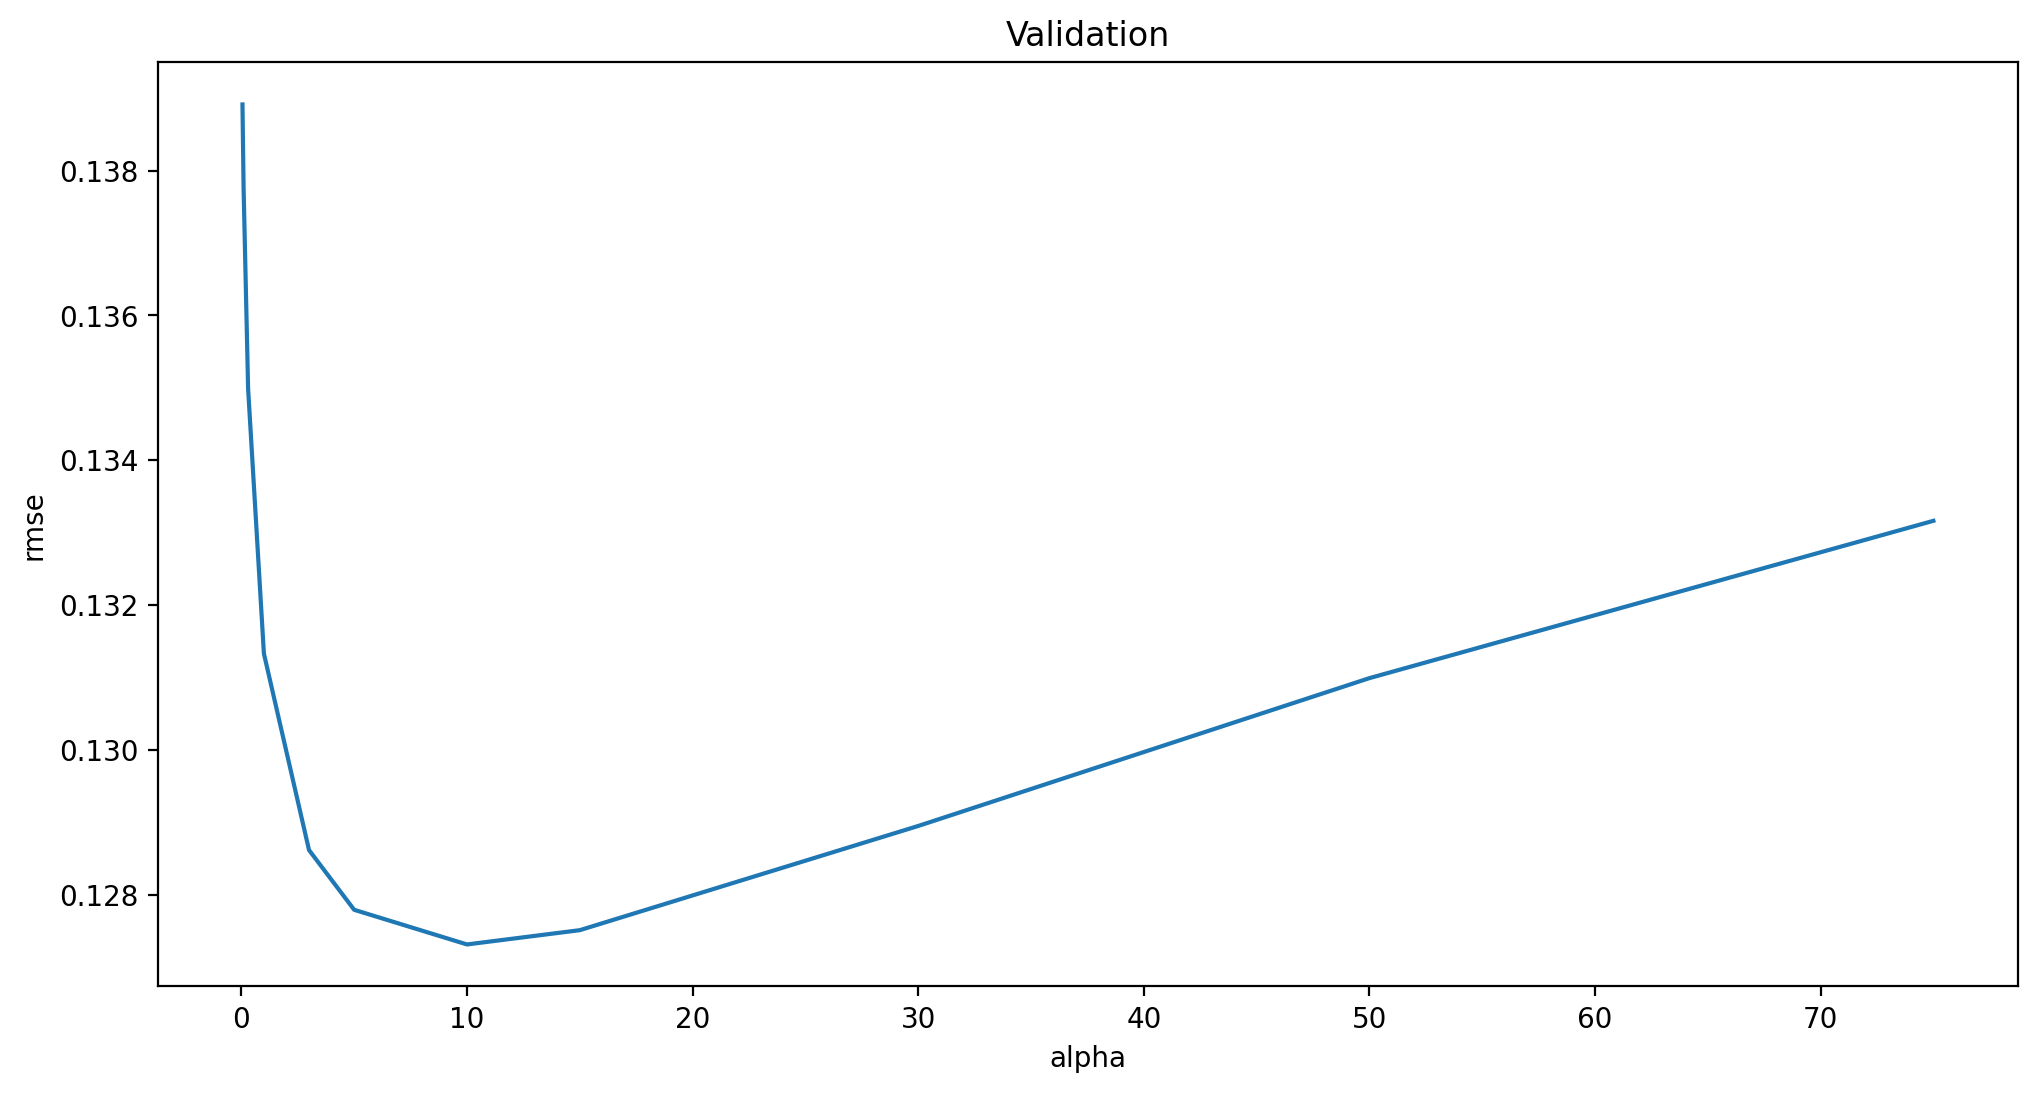

In [248]:
cv_ridge = pd.Series(cv_ridge, index = alphas)
cv_ridge.plot(title = "Validation")
plt.xlabel("alpha")
plt.ylabel("rmse")

Note the U-shaped curve. When alpha is too large the regularization is too strong and the model cannot capture all the complexities in the data. If however we let the model be too flexible (alpha too small) the model begins to overfit. A value of alpha = 10 is about right based on the plot above.

In [250]:
cv_ridge.min()

0.12731233261727548

For the Ridge regression we get a rmsle of about 0.127. Let's try out the Lasso model. We will do a slightly different approach here and use the built-in Lasso CV to figure out the best alpha for us. For some reason the alphas in Lasso CV are really the inverse or the alphas in Ridge

#### Explanation of code below

- L1 (LASSO) zeroes many coefficients - built-in feature selection
- Our bar chart shows top +/- effects (on log price). Typical positives: GrLivArea, quality dummies, premium neighborhoods; negatives: rare roof materials, adverse conditions, certain zoning dummies, etc.
- Delivers Req #3 (second model) and is a nice seque to Req #4 (indicator terms) since many one-hots are exactly that
- Caution: LASSO is scale-sensitive. Because our features are a mix of log-transformed numerics (still varying in scale) and one-hots (0/1), it's best to standardize numerics inside a pipline before LASSO so the penalty treats features comparably

In [252]:
model_lasso = LassoCV(alphas = [1, 0.1, 0.001, 0.0005]).fit(X_train, y)

In [254]:
rmse_cv(model_lasso).mean()

0.12256747906999563

The lasso performs even better so we'll just this one to predict on the next test set. Another thing about the Lasso is that it does feature selection for you - setting coefficients of features it deems unimportant to zero. Let's take a look at the coefficients

In [256]:
coef = pd.Series(model_lasso.coef_, index = X_train.columns)

In [258]:
print("Lasso picked " + str(sum(coef != 0)) + " variables and eliminated the other " + str(sum(coef ==0)) + " variables")

Lasso picked 110 variables and eliminated the other 177 variables


One thing to note here however is that the features selected are not necessarily the "correct" ones - especially since there are a lot of collinear features in this dataset. One idea to try here is to run Lasso a few times on bootstrapped samples and see how stable the feature selection is.

In [260]:
imp_coef = pd.concat([coef.sort_values().head(10),
                      coef.sort_values().tail(10)])

<Axes: >

Text(0.5, 1.0, 'Coefficients in the Lasso Model')

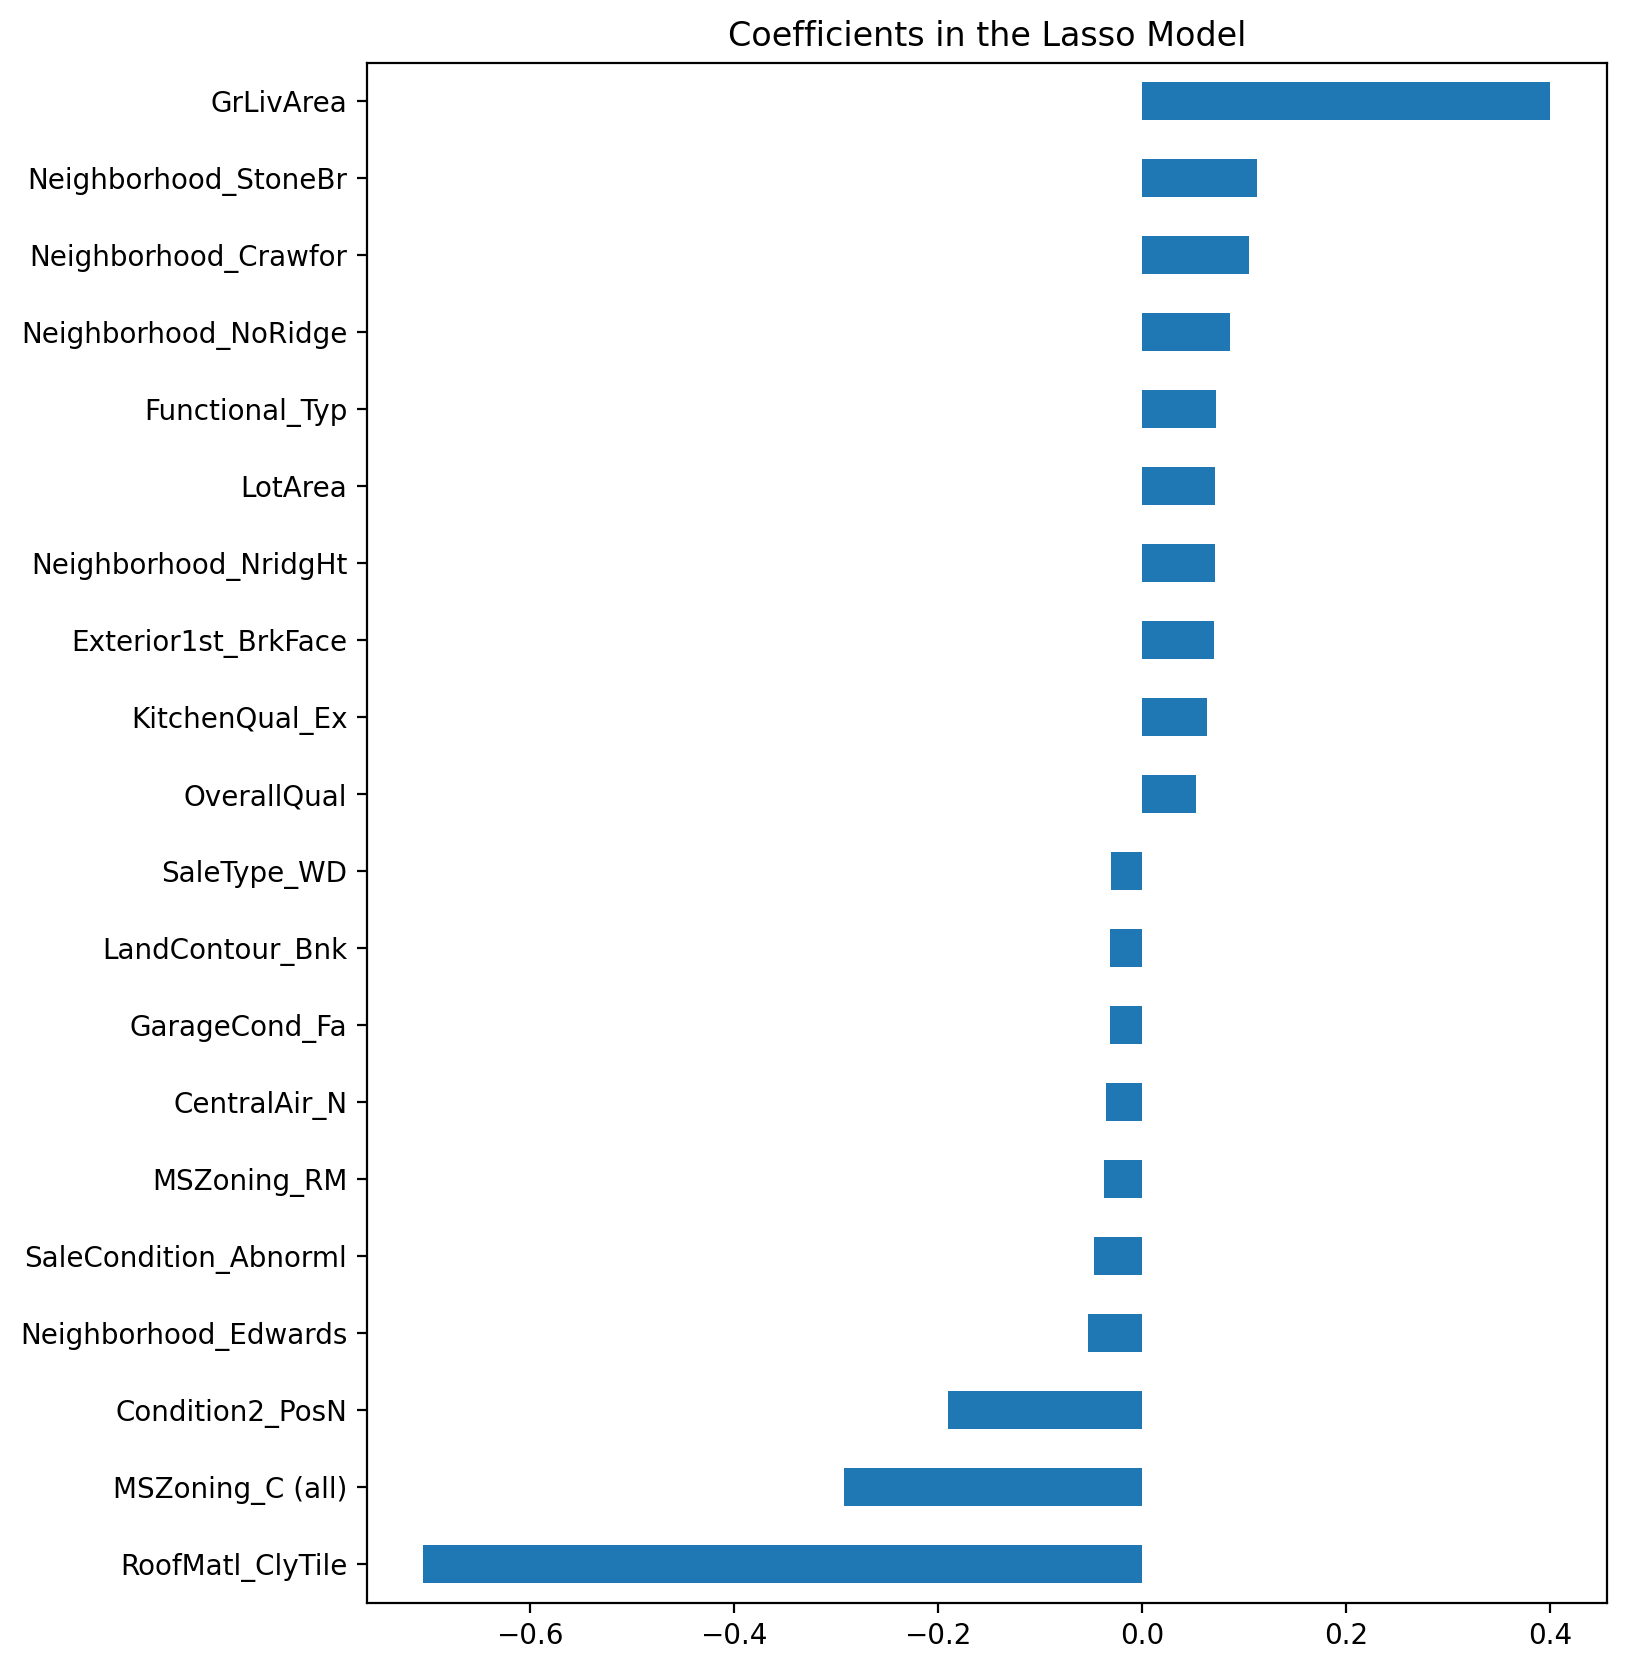

In [262]:
matplotlib.rcParams['figure.figsize'] = (8.0, 10.0)
imp_coef.plot(kind = "barh")
plt.title("Coefficients in the Lasso Model")

The most important positive feature is GrLivArea - the above ground area by square feet. This definitely makes sense. Then a few other location and quality features contribute positively. Some of the negative features make less sense and would be worth looking into more - it seems like they might come from unbalanced categorical variables.

Also note that unlike the feature importance you'd get from a random forest these are actual coefficients in your model - so you can say precisely why the predicted price is what it is. The only issue here is that we log_transformed both the target and the numeric features so the actual magnitudes are a bit hard to interpret and also the relationship is now multiplicative and not additive.

#### Explanation of code below

- The cloud is roughly centered at 0 (good), but you can see wider spread at higher-fitted values - mild heteroscedasicity (common for housing)
- Contributes to Req #6 (evaluate assumptions). Add a Q-Q plot for normality and residuals vs. key predictors to strengthen this section

<Axes: xlabel='preds', ylabel='residuals'>

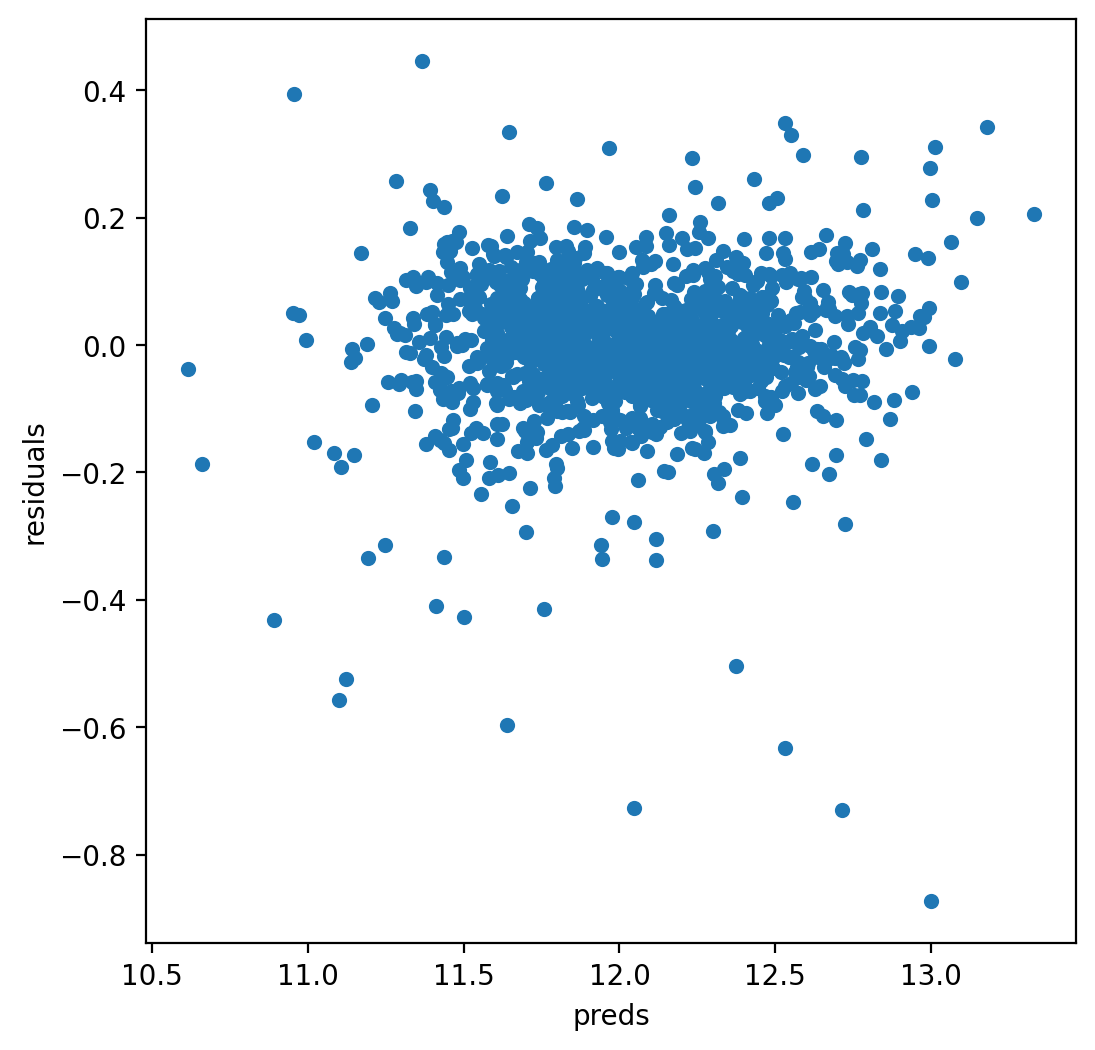

In [264]:
# Look at the residuals as well
matplotlib.rcParams['figure.figsize'] = (6.0, 6.0)

preds = pd.DataFrame({"preds":model_lasso.predict(X_train), "true":y})
preds["residuals"] = preds["true"] - preds["preds"]
preds.plot(x = "preds", y = "residuals",kind = "scatter")

## Adding an xgboost model:

In [163]:
#%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 1.9 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [266]:
import xgboost as xgb

#### Explanation of code below

- Wraps matrices in XGBoost's fast DMatrix
- Note: your y is log(SalePrice) from earlier, so the model learns in log space (good for RMSLE-style performance)
- Runs k-fold CV inside XGBoost (with default objective reg:squarederror)
- The plot shows train RMSE steadily decreasing (orange) while test RMSE (blue) drops then plateaus: classic overfitting gap after ~300-400 trees
- Early stopping would pick the round where test-rmse-mean is minimal; using that round (or something close) is best
- Train vs. Test RMSE curve
    - Train (orange) keeps dropping - the model fits training nose as trees increase
    - Test (blue) drops then plateaus around ~300-400 trees - diminishing returns; going far past the minimum hurts generalization
    - The gap is healthy - not huge - thanks to shallow trees (max_depth=2) and moderate learning rate

In [268]:
dtrain = xgb.DMatrix(X_train, label = y)
dtest = xgb.DMatrix(X_test)

params = {"max_depth":2, "eta":0.1}
model = xgb.cv(params, dtrain, num_boost_round=500, early_stopping_rounds=100)

<Axes: >

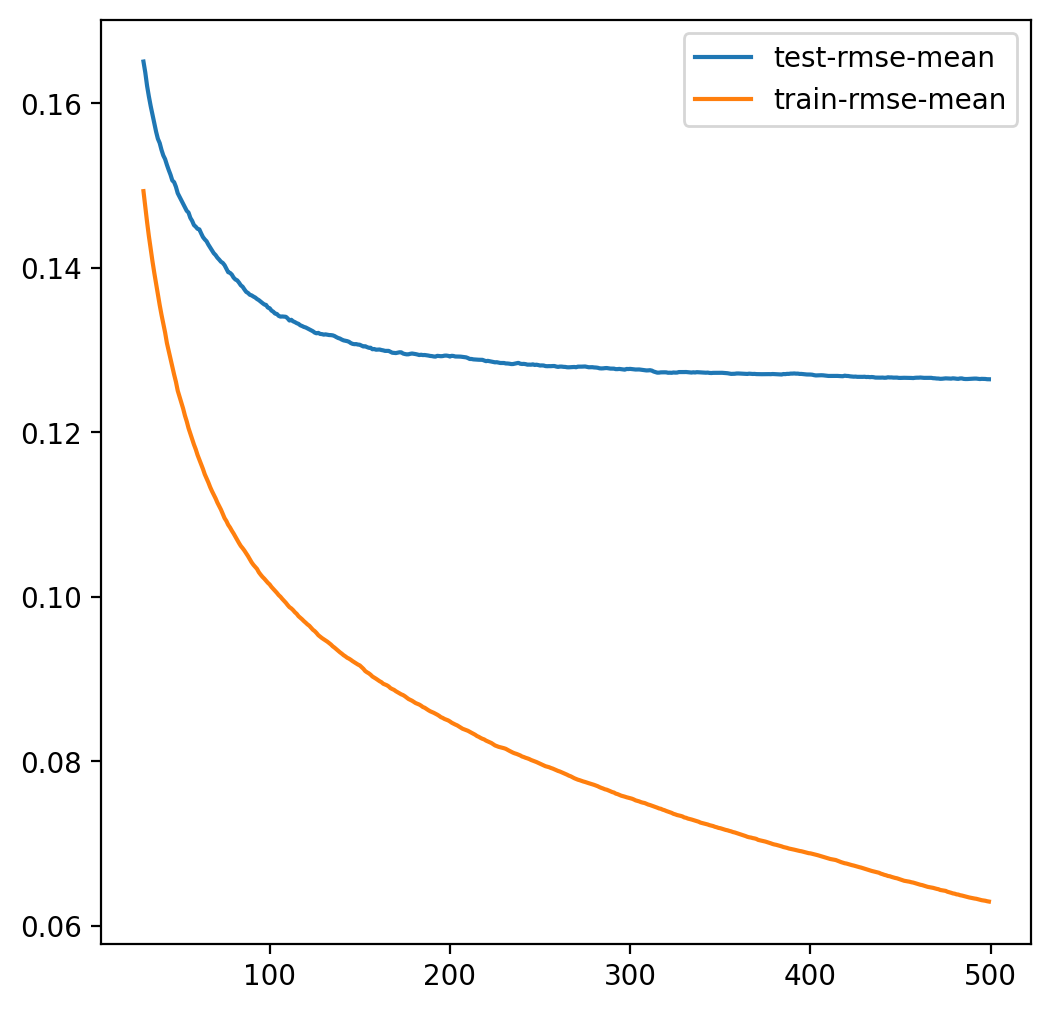

In [270]:
model.loc[30:,["test-rmse-mean", "train-rmse-mean"]].plot()

#### Explanation of code below

- Trains a final XGB on all training rows using a fixed n_estimators (chosen from the CV curve)
- You can also set n_estimators=best_round from xgb.cv for consistency

In [272]:
model_xgb = xgb.XGBRegressor(n_estimators=360, max_depth=2, learning_rate=0.1) #the params were tuned using xgb.cv
model_xgb.fit(X_train, y)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=360,
             n_jobs=None, num_parallel_tree=None, ...)

#### Explanation of code below

- Both models were trained on log(SalePrice); we correctly invert transform for the Kaggle submission

In [274]:
xgb_preds = np.expm1(model_xgb.predict(X_test))
lasso_preds = np.expm1(model_lasso.predict(X_test))

#### Explanation of code below

- Shows model agreement. Tight diagonal = both models predict similarly; the few off-diagonal points are where the models disagree (potential leverage for ensembling)
- LASSO vs. XGB prediction scatter
    - Points hugging the diagonal - the models largely agree (both capture size / quality / location)
    - Outliers above / below the diagonal - cases where one model sees a pattern the other misses (e.g., nonlinear interactions XGB captures, or linear signal LASSO generalizes better). Those cases are exactly why blending can help

<Axes: xlabel='xgb', ylabel='lasso'>

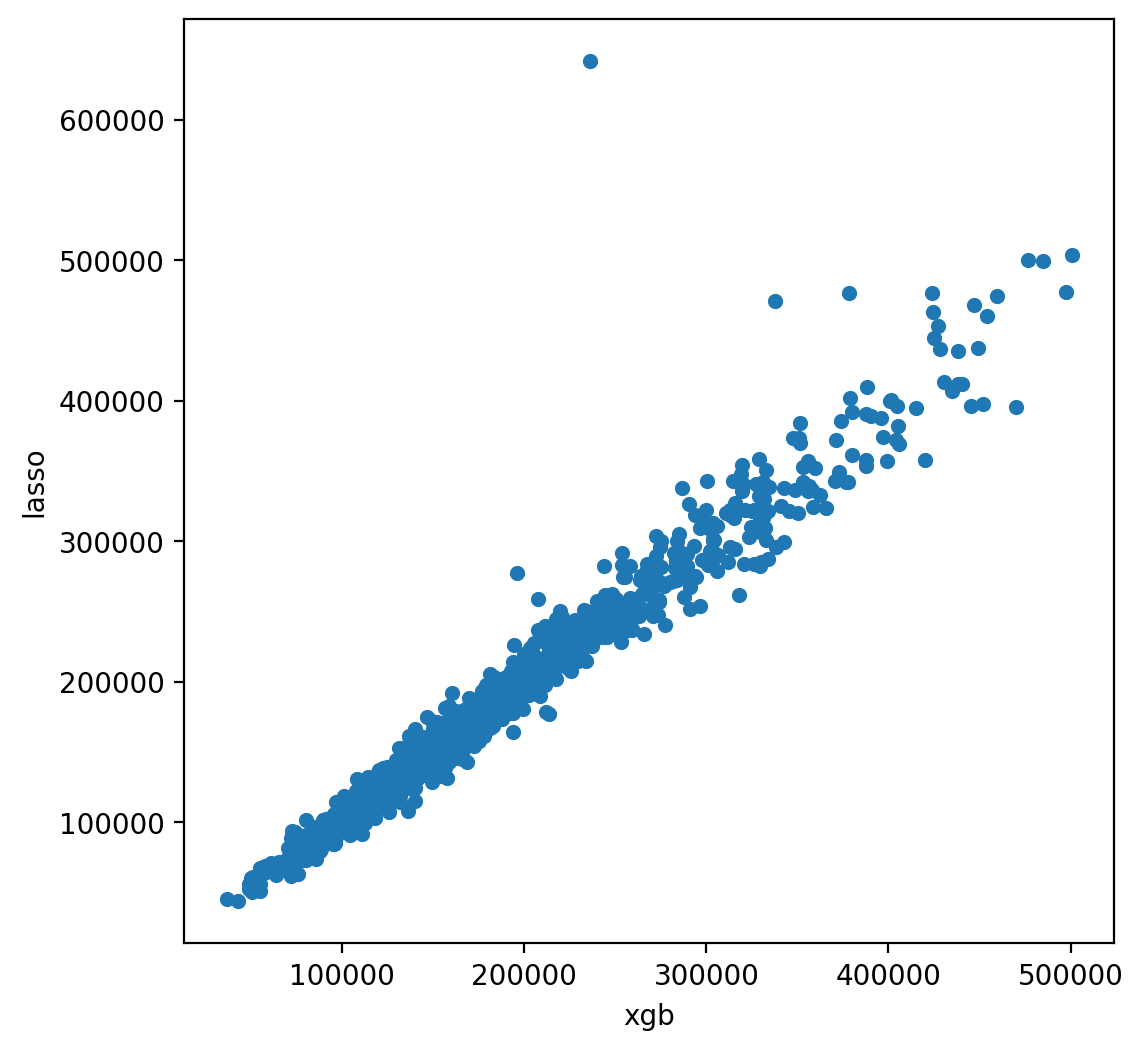

In [276]:
predictions = pd.DataFrame({"xgb":xgb_preds, "lasso":lasso_preds})
predictions.plot(x = "xgb", y = "lasso", kind = "scatter")

#### Explanation of code below

- Simple weighted average (blend): 70% LASSO + 30% XGB. Blending often reduces variance and improves leaderboard score
- Minor nits: the filename says "ridge" though it's a LASSO / XGB blend - rename to avoid confustion

In [278]:
preds = 0.7*lasso_preds + 0.3*xgb_preds

In [280]:
solution = pd.DataFrame({"id":test.Id, "SalePrice":preds})
solution.to_csv("lasso_xgb.csv", index = False)